# Tugas - Clustering dengan K-Means dan Hierarchical Clustering

| Nama | NRP |
|------|-----|
| Muhammad Nazwar Fakhrurrozy | 5054251040 |

## Deskripsi Tugas
Pada tugas ini, kalian akan membangun model clustering menggunakan K-Means dan Hierarchical Clustering untuk mengelompokkan posting Facebook penjual berdasarkan pola engagement-nya (like, komentar, share, dan reaksi emoji).

Dataset yang digunakan: `Live.csv` (Facebook Live Sellers in Thailand, UCI). Setiap baris adalah satu posting Facebook dari penjual fashion dan kosmetik di Thailand.

Tujuan utama dari tugas ini adalah memahami cara kerja algoritma clustering secara praktik, khususnya:
1. Penentuan jumlah cluster yang optimal (Elbow Method dan Silhouette Score) serta pengaruh transformasi log dan feature scaling pada K-Means
2. Perbedaan metode linkage dan pembacaan dendrogram pada Hierarchical Clustering
3. Perbandingan hasil K-Means dan Hierarchical Clustering

**Catatan:** Kolom `status_type` TIDAK boleh digunakan sebagai fitur clustering. Kolom ini hanya dipakai untuk membantu menafsirkan cluster pada tahap evaluasi.

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi fitur.
2. Preprocessing
   - Memproses data agar siap digunakan dalam clustering.
3. Eksperimen K-Means
   - Tentukan jumlah cluster dengan Elbow Method dan Silhouette Score, lalu bangun model K-Means.
4. Eksperimen Hierarchical Clustering
   - Amati dendrogram, bandingkan variasi linkage, lalu bangun model Agglomerative Clustering.
5. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
6. Analisis
7. Kesimpulan dan Saran

# 1. Persiapan Dataset dan Eksplorasi Awal

In [138]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, scipy, dll)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    calinski_harabasz_score,
    davies_bouldin_score,
    silhouette_score,
)
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 10

In [139]:
# Load dataset dan tampilkan informasi dasar: jumlah baris dan kolom, tipe data, statistik deskriptif, jumlah missing value, dan jumlah baris duplikat.
# Perhatikan apakah ada kolom yang seluruhnya kosong.
df = pd.read_csv("Live.csv")

print(f"Jumlah baris: {df.shape[0]}, Jumlah kolom: {df.shape[1]}\n")

df.info()

display(df.describe().T)

missing_series = df.isnull().sum()
display(missing_series[missing_series > 0])

print(f"\nJumlah baris duplikat (semua kolom): {df.duplicated().sum()}")
print(
    "Jumlah duplikat jika status_id diabaikan:"
    f" {df.drop(columns=['status_id']).duplicated().sum()}"
)

Jumlah baris: 7050, Jumlah kolom: 16

<class 'pandas.DataFrame'>
RangeIndex: 7050 entries, 0 to 7049
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   status_id         7050 non-null   int64  
 1   status_type       7050 non-null   str    
 2   status_published  7050 non-null   str    
 3   num_reactions     7050 non-null   int64  
 4   num_comments      7050 non-null   int64  
 5   num_shares        7050 non-null   int64  
 6   num_likes         7050 non-null   int64  
 7   num_loves         7050 non-null   int64  
 8   num_wows          7050 non-null   int64  
 9   num_hahas         7050 non-null   int64  
 10  num_sads          7050 non-null   int64  
 11  num_angrys        7050 non-null   int64  
 12  Column1           0 non-null      float64
 13  Column2           0 non-null      float64
 14  Column3           0 non-null      float64
 15  Column4           0 non-null      float64
dtypes: float64(4), 

,count,mean,std,min,25%,50%,75%,max
status_id,7050.0,3525.500000,2035.304031,1.0,1763.25,3525.5,5287.75,7050.0
num_reactions,7050.0,230.117163,462.625309,0.0,17.00,59.5,219.00,4710.0
num_comments,7050.0,224.356028,889.636820,0.0,0.00,4.0,23.00,20990.0
num_shares,7050.0,40.022553,131.599965,0.0,0.00,0.0,4.00,3424.0
num_likes,7050.0,215.043121,449.472357,0.0,17.00,58.0,184.75,4710.0
num_loves,7050.0,12.728652,39.972930,0.0,0.00,0.0,3.00,657.0
num_wows,7050.0,1.289362,8.719650,0.0,0.00,0.0,0.00,278.0
num_hahas,7050.0,0.696454,3.957183,0.0,0.00,0.0,0.00,157.0
num_sads,7050.0,0.243688,1.597156,0.0,0.00,0.0,0.00,51.0
num_angrys,7050.0,0.113191,0.726812,0.0,0.00,0.0,0.00,31.0


Column1    7050
Column2    7050
Column3    7050
Column4    7050
dtype: int64


Jumlah baris duplikat (semua kolom): 0
Jumlah duplikat jika status_id diabaikan: 54


,Min,Median,Max,Skewness,Proporsi Nilai 0 (%)
num_reactions,0,59.5,4710,3.738452,1.716312
num_comments,0,4.0,20990,9.028850,30.056738
num_shares,0,0.0,3424,7.099332,55.475177
num_likes,0,58.0,4710,3.919128,1.787234
num_loves,0,0.0,657,6.004845,60.000000
num_wows,0,0.0,278,18.246813,75.290780
num_hahas,0,0.0,157,20.305741,83.914894
num_sads,0,0.0,51,17.578868,91.390071
num_angrys,0,0.0,31,19.507129,94.000000


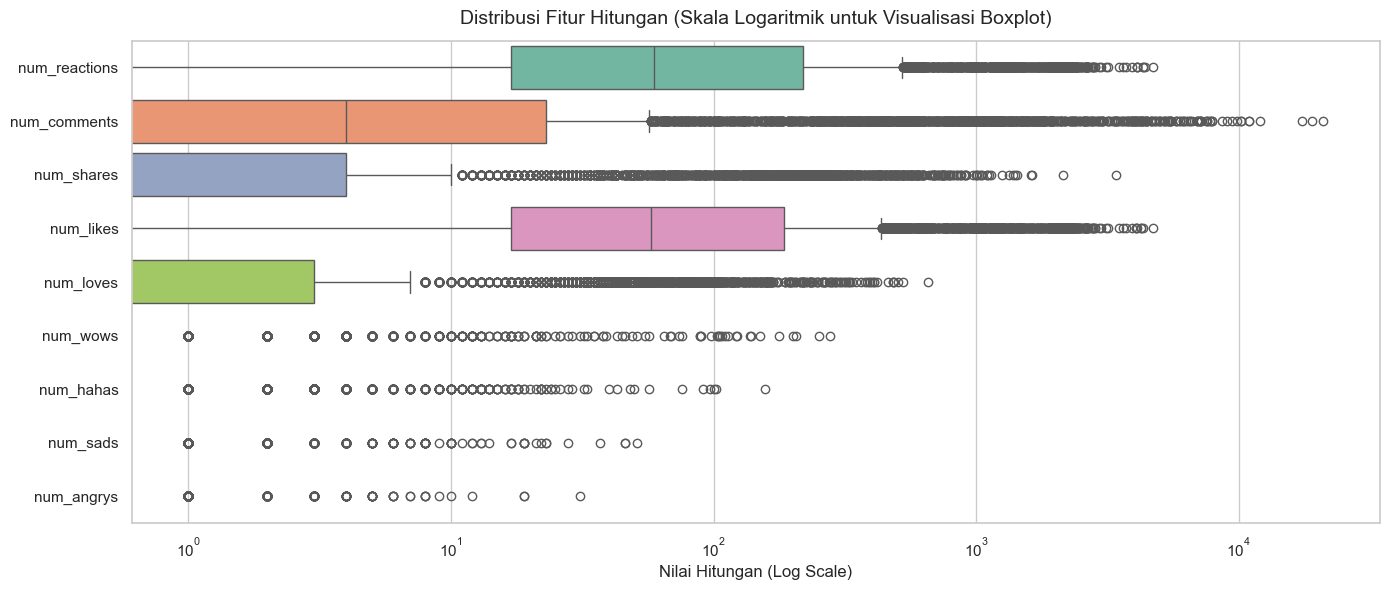

In [140]:
# Tampilkan distribusi fitur hitungan (histogram atau boxplot).
# Perhatikan skewness, proporsi nilai nol, dan perbedaan skala antar fitur (misalnya num_comments vs num_angrys), karena ini penting untuk tahap preprocessing.
num_cols = [
    "num_reactions",
    "num_comments",
    "num_shares",
    "num_likes",
    "num_loves",
    "num_wows",
    "num_hahas",
    "num_sads",
    "num_angrys",
]

skewness = df[num_cols].skew()
zero_percent = (df[num_cols] == 0).mean() * 100

summary_dist = pd.DataFrame(
    {
        "Min": df[num_cols].min(),
        "Median": df[num_cols].median(),
        "Max": df[num_cols].max(),
        "Skewness": skewness,
        "Proporsi Nilai 0 (%)": zero_percent,
    }
)

display(summary_dist)

plt.figure(figsize=(14, 6))
sns.boxplot(data=df[num_cols], orient="h", palette="Set2")
plt.xscale("log")
plt.title(
    "Distribusi Fitur Hitungan (Skala Logaritmik untuk Visualisasi Boxplot)",
    fontsize=14,
    pad=12,
)
plt.xlabel("Nilai Hitungan (Log Scale)")
plt.tight_layout()
plt.show()

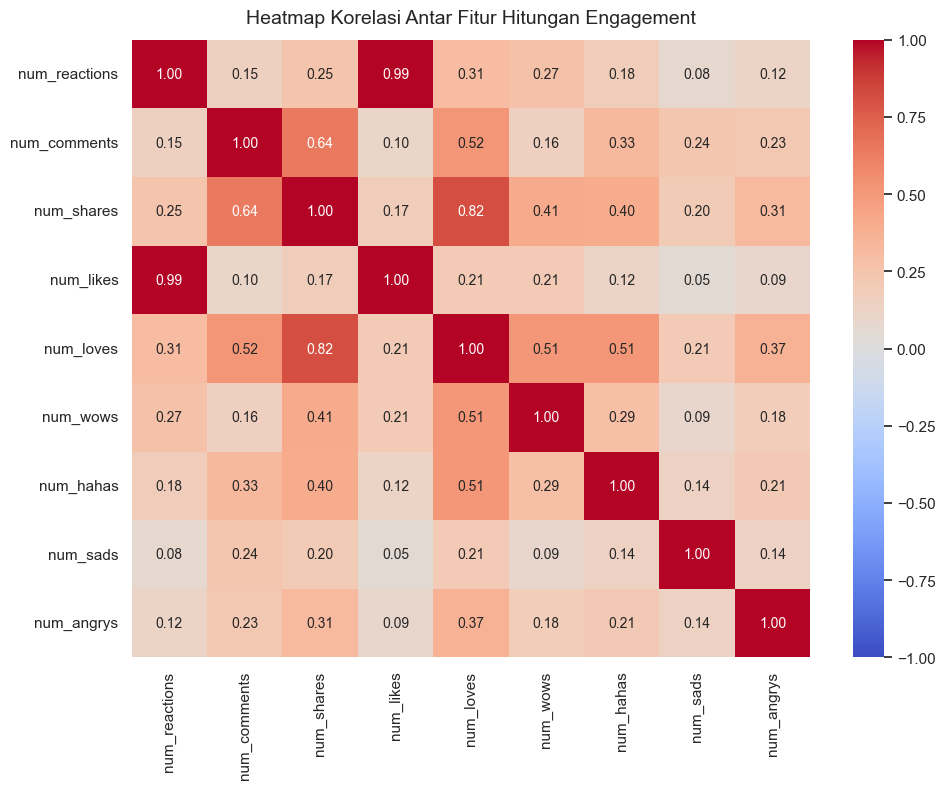

In [141]:
# Tampilkan heatmap korelasi antar fitur hitungan.
# Perhatikan fitur-fitur yang berkorelasi sangat tinggi atau saling berkaitan secara definisi (redundan), karena memengaruhi perhitungan jarak pada clustering.
plt.figure(figsize=(10, 8))
corr_matrix = df[num_cols].corr()

sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Heatmap Korelasi Antar Fitur Hitungan Engagement", fontsize=14, pad=12)
plt.tight_layout()
plt.show()

,total_posting,posting_ber_emoji,proporsi_emoji (%)
year,,,
2012,589,0,0.000000
2013,500,0,0.000000
2014,233,0,0.000000
2015,337,0,0.000000
2016,588,400,68.027211
2017,2253,1221,54.194407
2018,2550,1473,57.764706


C:\Users\Nazwar\AppData\Local\Temp\ipykernel_16232\3493672797.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


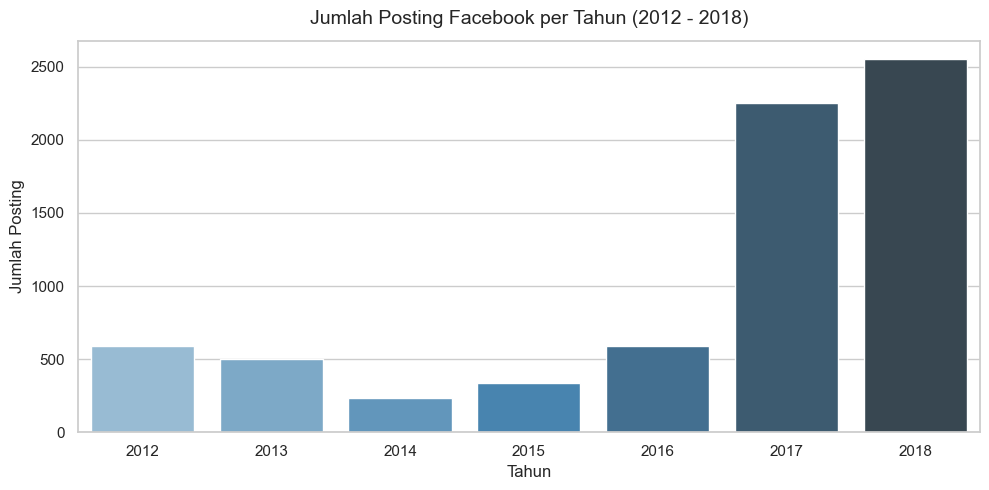

In [142]:
# Ubah kolom status_published menjadi datetime.
# Tampilkan jumlah posting dan proporsi posting yang memiliki reaksi emoji pada setiap tahun.
# Amati apakah ada perubahan pola dari tahun ke tahun.
df["status_published"] = pd.to_datetime(df["status_published"])
df["year"] = df["status_published"].dt.year

emoji_cols = ["num_loves", "num_wows", "num_hahas", "num_sads", "num_angrys"]
df["has_emoji"] = df[emoji_cols].sum(axis=1) > 0

yearly_summary = df.groupby("year").agg(
    total_posting=("status_id", "count"),
    posting_ber_emoji=("has_emoji", "sum"),
    proporsi_emoji=("has_emoji", "mean"),
)
yearly_summary["proporsi_emoji (%)"] = yearly_summary["proporsi_emoji"] * 100

display(yearly_summary[["total_posting", "posting_ber_emoji", "proporsi_emoji (%)"]])

plt.figure(figsize=(10, 5))
sns.barplot(
    x=yearly_summary.index, y=yearly_summary["total_posting"], palette="Blues_d"
)
plt.title("Jumlah Posting Facebook per Tahun (2012 - 2018)", fontsize=14, pad=12)
plt.xlabel("Tahun")
plt.ylabel("Jumlah Posting")
plt.tight_layout()
plt.show()

C:\Users\Nazwar\AppData\Local\Temp\ipykernel_16232\3214511402.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


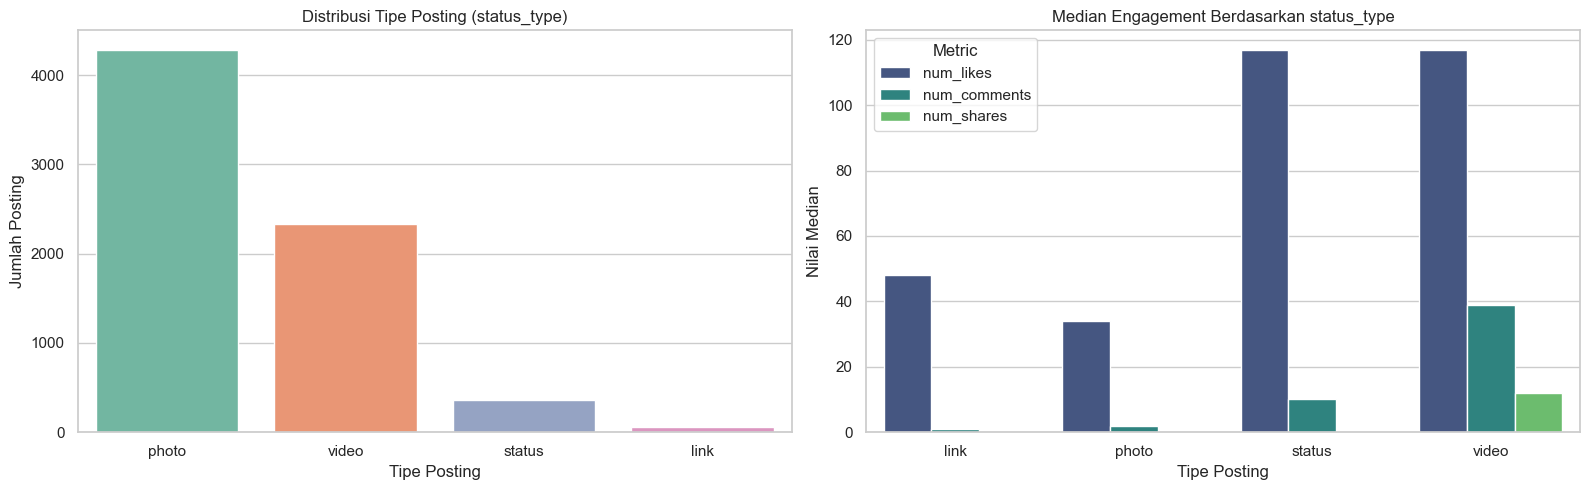

,status_type,num_likes,num_comments,num_shares
0,link,48.0,1.0,0.0
1,photo,34.0,2.0,0.0
2,status,117.0,10.0,0.0
3,video,117.0,39.0,12.0


In [143]:
# Tampilkan distribusi status_type dalam bentuk bar plot.
# Bandingkan median num_likes, num_comments, dan num_shares untuk setiap status_type.
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.countplot(
    data=df,
    x="status_type",
    ax=axes[0],
    palette="Set2",
    order=df["status_type"].value_counts().index,
)
axes[0].set_title("Distribusi Tipe Posting (status_type)", fontsize=12)
axes[0].set_xlabel("Tipe Posting")
axes[0].set_ylabel("Jumlah Posting")

status_engagement = (
    df.groupby("status_type")[["num_likes", "num_comments", "num_shares"]]
    .median()
    .reset_index()
)
status_melted = status_engagement.melt(
    id_vars="status_type", var_name="Metric", value_name="Median_Value"
)

sns.barplot(
    data=status_melted,
    x="status_type",
    y="Median_Value",
    hue="Metric",
    ax=axes[1],
    palette="viridis",
)
axes[1].set_title("Median Engagement Berdasarkan status_type", fontsize=12)
axes[1].set_xlabel("Tipe Posting")
axes[1].set_ylabel("Nilai Median")

plt.tight_layout()
plt.show()

display(status_engagement)

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

# 2. Preprocessing

In [144]:
# Hapus kolom yang seluruhnya kosong.
# Periksa dan tangani baris duplikat (ingat bahwa status_id selalu unik untuk tiap baris).
# Periksa juga missing value dan outlier ekstrem, lalu tentukan penanganannya.
df = df.dropna(how="all", axis=1)

print("Jumlah missing values per kolom:")
display(df.isnull().sum())

duplicate_count = df.drop(columns=["status_id"]).duplicated().sum()
print(f"Jumlah baris duplikat tanpa status_id: {duplicate_count}")

df = df.drop_duplicates(subset=df.columns.difference(["status_id"])).reset_index(
    drop=True
)

print(f"Ukuran dataset setelah pembersihan: {df.shape}")

Jumlah missing values per kolom:


status_id           0
status_type         0
status_published    0
num_reactions       0
num_comments        0
num_shares          0
num_likes           0
num_loves           0
num_wows            0
num_hahas           0
num_sads            0
num_angrys          0
year                0
has_emoji           0
dtype: int64

Jumlah baris duplikat tanpa status_id: 54
Ukuran dataset setelah pembersihan: (6996, 14)


In [145]:
# Pisahkan status_type dan status_published (untuk interpretasi cluster pada tahap evaluasi) dari fitur yang akan dipakai untuk clustering.
# Hapus kolom yang tidak relevan untuk clustering (misalnya status_id).
# Periksa apakah ada fitur yang redundan (misalnya fitur yang merupakan penjumlahan fitur lain) atau yang sebagian besar bernilai nol.
# Pilih fitur yang akan dipakai untuk clustering. Pertimbangkan untuk menggabungkan fitur yang sparse.
# Catatan: K-Means dan Hierarchical Clustering berbasis jarak, sehingga semua fitur harus berupa angka.
meta_cols = ["status_type", "status_published"]
df_meta = df[meta_cols].copy()

df["num_other_emojis"] = (
    df["num_wows"] + df["num_hahas"] + df["num_sads"] + df["num_angrys"]
)

selected_features = [
    "num_likes",
    "num_comments",
    "num_shares",
    "num_loves",
    "num_other_emojis",
]

X_raw = df[selected_features].copy()

print("Fitur terpilih untuk clustering:")
display(X_raw.head())

Fitur terpilih untuk clustering:


,num_likes,num_comments,num_shares,num_loves,num_other_emojis
0,432,512,262,92,5
1,150,0,0,0,0
2,204,236,57,21,2
3,111,0,0,0,0
4,204,0,0,9,0


**Fitur yang dipilih untuk clustering:** (isi daftar fitur yang kalian pilih beserta alasannya, termasuk keputusan terhadap kolom yang redundan atau banyak bernilai nol)

## fitur yang dipilih

num_likes: Mewakili bentuk interaksi apresiasi dasar yang paling dominan pada posting.

num_comments: Mewakili tingkat keterlibatan dan percakapan audiens pada posting.

num_shares: Mewakili jangkauan dan persebaran konten oleh audiens.

num_loves: Mewakili ekspresi reaksi positif yang paling sering digunakan selain like.

num_other_emojis: Penggabungan dari num_wows, num_hahas, num_sads, dan num_angrys karena masing-masing fitur ini sangat sparse dengan persentase nilai nol melebihi 75% hingga 94%.

## Eliminasi fitur

status_id: Dihapus karena hanya berfungsi sebagai identifikasi unik dan tidak memiliki makna matematis.

num_reactions: Dihapus karena bersifat redundan (multikolinearitas sempurna, r = 0,99 dengan num_likes), sebab nilainya merupakan hasil penjumlahan dari num_likes dan reaksi emoji lainnya.

status_type & status_published: Dipisahkan dari matriks masukan clustering dan disimpan sebagai metadata untuk membantu analisis interpretasi profil cluster pada tahap evaluasi.


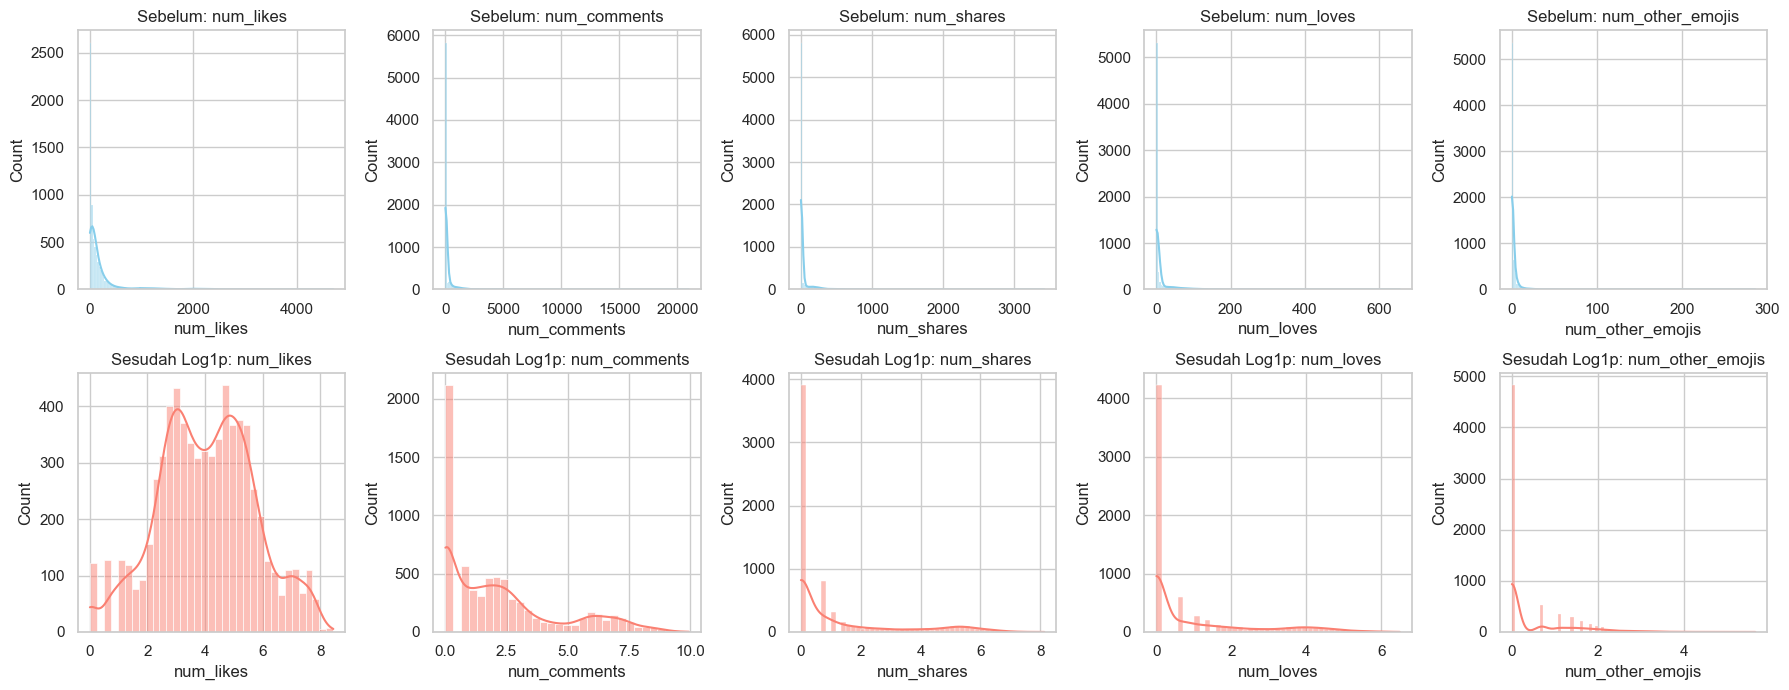

In [146]:
# Fitur hitungan pada dataset ini sangat miring (skewed). Terapkan transformasi log1p pada fitur yang dipilih.
# Tampilkan distribusi fitur sebelum dan sesudah transformasi untuk melihat perbedaannya.
X_log = np.log1p(X_raw)

fig, axes = plt.subplots(2, 5, figsize=(18, 7))

for i, col in enumerate(selected_features):
    sns.histplot(X_raw[col], ax=axes[0, i], kde=True, color="skyblue")
    axes[0, i].set_title(f"Sebelum: {col}")

    sns.histplot(X_log[col], ax=axes[1, i], kde=True, color="salmon")
    axes[1, i].set_title(f"Sesudah Log1p: {col}")

plt.tight_layout()
plt.show()

In [147]:
# Lakukan feature scaling (misalnya StandardScaler) pada fitur hasil transformasi log dan simpan hasilnya (X_log_scaled).
# Simpan juga versi lain untuk keperluan perbandingan pada bagian 3.1:
# - X_raw: fitur mentah tanpa transformasi dan tanpa scaling
# - X_raw_scaled: fitur mentah dengan scaling saja
scaler_raw = StandardScaler()
X_raw_scaled = pd.DataFrame(
    scaler_raw.fit_transform(X_raw), columns=selected_features
)

scaler_log = StandardScaler()
X_log_scaled = pd.DataFrame(
    scaler_log.fit_transform(X_log), columns=selected_features
)

print("Penyiapan varian data selesai:")
print(f"1. X_raw shape: {X_raw.shape}")
print(f"2. X_raw_scaled shape: {X_raw_scaled.shape}")
print(f"3. X_log_scaled shape: {X_log_scaled.shape}")

Penyiapan varian data selesai:
1. X_raw shape: (6996, 5)
2. X_raw_scaled shape: (6996, 5)
3. X_log_scaled shape: (6996, 5)


# 3. Eksperimen K-Means

## 3.1 Pengaruh Transformasi Log dan Feature Scaling pada K-Means

K-Means mengelompokkan data dengan meminimalkan jarak antara titik dan centroid cluster. Pada bagian ini kalian akan mengamati bagaimana transformasi log dan scaling memengaruhi hasil clustering.

In [148]:
# Latih K-Means dengan jumlah cluster yang sama (misalnya k=3) pada tiga versi data:
# (1) X_raw (mentah tanpa scaling), (2) X_raw_scaled (mentah dengan scaling), dan (3) X_log_scaled (log dan scaling).
# Gunakan random_state dan n_init yang sama agar perbandingan adil.
kmeans_raw = KMeans(n_clusters=3, random_state=42, n_init=10).fit(X_raw)
kmeans_raw_scaled = KMeans(n_clusters=3, random_state=42, n_init=10).fit(
    X_raw_scaled
)
kmeans_log_scaled = KMeans(n_clusters=3, random_state=42, n_init=10).fit(
    X_log_scaled
)

labels_raw = kmeans_raw.labels_
labels_raw_scaled = kmeans_raw_scaled.labels_
labels_log_scaled = kmeans_log_scaled.labels_

In [149]:
# Bandingkan ketiga hasil tersebut: jumlah anggota tiap cluster dan Silhouette Score.
# Hitung Silhouette ketiganya pada ruang yang sama (misalnya X_log_scaled) agar perbandingannya adil.
# Amati fitur mana yang mendominasi varians pada data tanpa scaling, dan apakah ada cluster yang sangat kecil atau sangat besar.
score_raw = silhouette_score(X_log_scaled, labels_raw)
score_raw_scaled = silhouette_score(X_log_scaled, labels_raw_scaled)
score_log_scaled = silhouette_score(X_log_scaled, labels_log_scaled)

dist_raw = pd.Series(labels_raw).value_counts().sort_index().to_dict()
dist_raw_scaled = (
    pd.Series(labels_raw_scaled).value_counts().sort_index().to_dict()
)
dist_log_scaled = (
    pd.Series(labels_log_scaled).value_counts().sort_index().to_dict()
)

comparison_df = pd.DataFrame(
    {
        "Versi Data": ["X_raw", "X_raw_scaled", "X_log_scaled"],
        "Silhouette Score": [score_raw, score_raw_scaled, score_log_scaled],
        "Distribusi Anggota Cluster": [
            dist_raw,
            dist_raw_scaled,
            dist_log_scaled,
        ],
    }
)

display(comparison_df)

,Versi Data,Silhouette Score,Distribusi Anggota Cluster
0,X_raw,0.298186,"{0: 6392, 1: 137, 2: 467}"
1,X_raw_scaled,0.241593,"{0: 292, 1: 6331, 2: 373}"
2,X_log_scaled,0.432512,"{0: 2200, 1: 3647, 2: 1149}"


## 3.2 Menentukan Jumlah Cluster dengan Elbow Method

Elbow Method memplot nilai inertia (Within-Cluster Sum of Squares) terhadap jumlah cluster k. Titik "siku" pada grafik menunjukkan nilai k setelah mana penambahan cluster tidak lagi memberikan penurunan inertia yang berarti.

In [150]:
# Latih K-Means pada X_log_scaled untuk rentang k tertentu (misalnya k = 2 sampai 10).
# Simpan nilai inertia untuk setiap k.
k_list = list(range(2, 11))
inertia_list = []

for k in k_list:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_log_scaled)
    inertia_list.append(model.inertia_)

elbow_df = pd.DataFrame({"Jumlah Cluster (k)": k_list, "Inertia": inertia_list})

display(elbow_df)

,Jumlah Cluster (k),Inertia
0,2,15075.909378
1,3,10144.120533
2,4,8448.677163
3,5,7360.895212
4,6,6348.502971
5,7,5737.203550
6,8,5306.316121
7,9,4878.489016
8,10,4584.487221


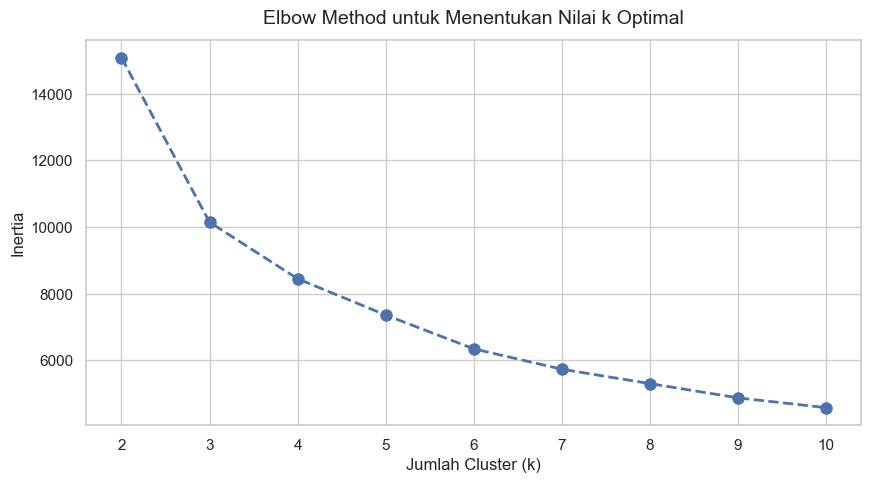

In [151]:
# Plot grafik Elbow (k vs inertia).
# Amati pada nilai k berapa terbentuk "siku".
# (Opsional) Gunakan library kneed (KneeLocator) untuk mendeteksi elbow secara otomatis, lalu bandingkan dengan pengamatan kalian.
plt.figure(figsize=(10, 5))
plt.plot(
    k_list,
    inertia_list,
    marker="o",
    linestyle="--",
    color="b",
    linewidth=2,
    markersize=8,
)
plt.title("Elbow Method untuk Menentukan Nilai k Optimal", fontsize=14, pad=12)
plt.xlabel("Jumlah Cluster (k)")
plt.ylabel("Inertia")
plt.xticks(k_list)
plt.grid(True)
plt.show()

## 3.3 Menentukan Jumlah Cluster dengan Silhouette Score

Silhouette Score mengukur seberapa mirip sebuah titik dengan clusternya sendiri dibandingkan dengan cluster lain. Nilainya berkisar dari -1 sampai 1, semakin tinggi semakin baik.

In [152]:
# Hitung Silhouette Score untuk setiap nilai k pada rentang yang sama dengan Elbow Method.
# Simpan hasilnya dalam list atau dictionary agar mudah diplot.
k_list = list(range(2, 11))
silhouette_scores = []

for k in k_list:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_log_scaled)
    score = silhouette_score(X_log_scaled, labels)
    silhouette_scores.append(score)

sil_df = pd.DataFrame(
    {"Jumlah Cluster (k)": k_list, "Silhouette Score": silhouette_scores}
)

display(sil_df)

,Jumlah Cluster (k),Silhouette Score
0,2,0.587056
1,3,0.432512
2,4,0.412154
3,5,0.398853
4,6,0.304860
5,7,0.310379
6,8,0.298920
7,9,0.302176
8,10,0.298377


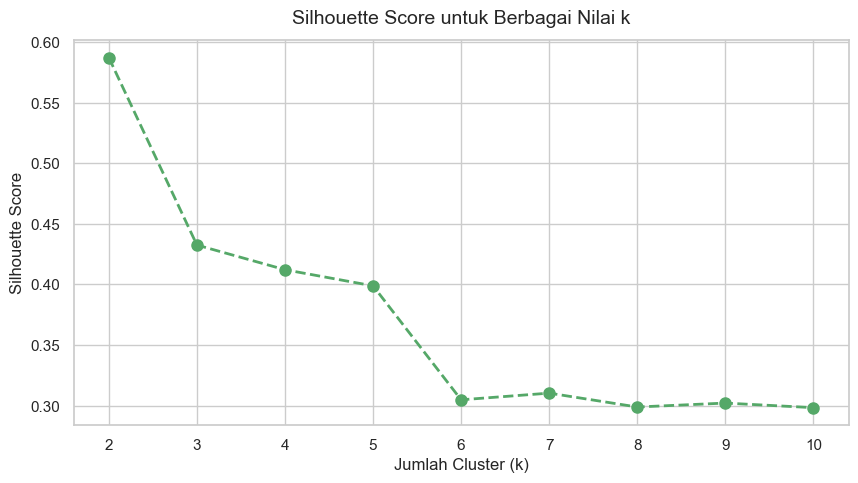

In [153]:
# Plot grafik Silhouette Score terhadap k.
# Tentukan nilai k terbaik dengan mempertimbangkan hasil Elbow Method dan Silhouette Score, lalu jelaskan alasannya pada cell markdown di bawah.
plt.figure(figsize=(10, 5))
plt.plot(
    k_list,
    silhouette_scores,
    marker="o",
    linestyle="--",
    color="g",
    linewidth=2,
    markersize=8,
)
plt.title("Silhouette Score untuk Berbagai Nilai k", fontsize=14, pad=12)
plt.xlabel("Jumlah Cluster (k)")
plt.ylabel("Silhouette Score")
plt.xticks(k_list)
plt.grid(True)
plt.show()

**Pilihan k untuk K-Means:** k=3

Nilai k = 3 dipilih karena grafik Elbow menunjukkan penurunan inertia melambat drastis pada titik ini. Pembagian 3 cluster memisahkan data engagement secara alami menjadi kelompok interaksi rendah, sedang, dan tinggi

## 3.4 Model K-Means Final

In [154]:
# Latih model K-Means final dengan nilai k terbaik yang kalian pilih pada X_log_scaled.
# Simpan label cluster hasil prediksi untuk keperluan evaluasi.
kmeans_final = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans_labels = kmeans_final.fit_predict(X_log_scaled)

df["kmeans_cluster"] = kmeans_labels

print("Model K-Means final berhasil dilatih.")
print(
    "Distribusi jumlah anggota per cluster:",
    pd.Series(kmeans_labels).value_counts().to_dict(),
)

Model K-Means final berhasil dilatih.
Distribusi jumlah anggota per cluster: {1: 3647, 0: 2200, 2: 1149}


In [155]:
# Buat profil setiap cluster pada data ASLI (sebelum transformasi log dan scaling): tampilkan median (dan rata-rata) tiap fitur per cluster beserta jumlah anggotanya.
# Gunakan median karena distribusi fitur sangat miring.
# Ini membantu menginterpretasikan karakteristik tiap cluster.
cluster_median = df.groupby("kmeans_cluster")[selected_features].median()
cluster_median["jumlah_anggota"] = df["kmeans_cluster"].value_counts()

cluster_mean = df.groupby("kmeans_cluster")[selected_features].mean()
cluster_mean["jumlah_anggota"] = df["kmeans_cluster"].value_counts()

display(cluster_median)

display(cluster_mean)

,num_likes,num_comments,num_shares,num_loves,num_other_emojis,jumlah_anggota
kmeans_cluster,,,,,,
0,204.5,11.0,1.0,1.0,0.0,2200
1,18.0,0.0,0.0,0.0,0.0,3647
2,177.0,703.0,174.0,51.0,4.0,1149


,num_likes,num_comments,num_shares,num_loves,num_other_emojis,jumlah_anggota
kmeans_cluster,,,,,,
0,458.457273,28.015455,5.029091,2.624545,1.574545,2200
1,23.003016,2.216891,0.545380,0.144502,0.064162,3647
2,328.040905,1313.246301,233.870322,72.190601,10.752829,1149


# 4. Eksperimen Hierarchical Clustering

## 4.1 Dendrogram

Hierarchical Clustering (Agglomerative) memulai dengan setiap titik sebagai cluster tersendiri, lalu menggabungkan dua cluster terdekat secara berulang hingga tersisa satu cluster. Dendrogram memvisualisasikan proses penggabungan tersebut.

In [156]:
# Hitung linkage matrix (scipy.cluster.hierarchy.linkage) dengan metode ward pada X_log_scaled.
# Dataset berisi sekitar 7.000 baris sehingga proses ini masih ringan dan tidak perlu dilakukan sampling.
linkage_matrix = linkage(X_log_scaled, method="ward")

print("Linkage matrix berhasil dihitung.")

Linkage matrix berhasil dihitung.


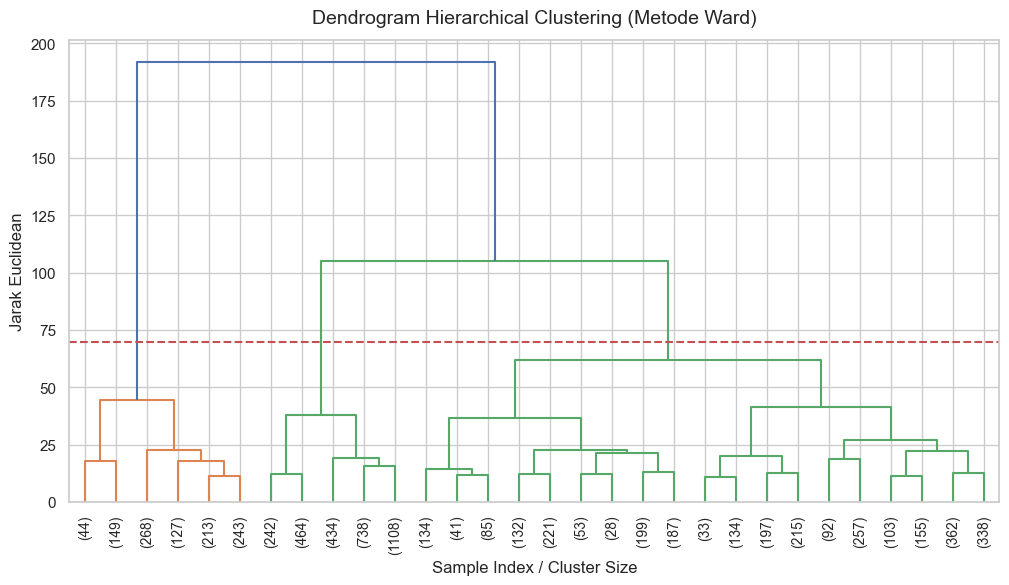

In [157]:
# Tampilkan dendrogram dari linkage matrix di atas.
# Batasi tampilan agar mudah dibaca (misalnya truncate_mode='lastp' atau p=30).
# Amati pada ketinggian berapa sebaiknya dendrogram dipotong untuk menentukan jumlah cluster.
plt.figure(figsize=(12, 6))
dendrogram(linkage_matrix, truncate_mode="lastp", p=30, leaf_rotation=90)
plt.title("Dendrogram Hierarchical Clustering (Metode Ward)", fontsize=14, pad=12)
plt.xlabel("Sample Index / Cluster Size")
plt.ylabel("Jarak Euclidean")
plt.axhline(y=70, color="r", linestyle="--")
plt.show()

## 4.2 Perbandingan Metode Linkage

Linkage menentukan cara jarak antar cluster dihitung. Pada bagian ini kalian akan membandingkan empat metode linkage: ward, complete, average, dan single.

In [158]:
# Latih AgglomerativeClustering dengan masing-masing linkage (ward, complete, average, single).
# Gunakan jumlah cluster yang sama untuk semua linkage agar perbandingan adil.
linkages = ["ward", "complete", "average", "single"]
linkage_models = {}

for link in linkages:
    model = AgglomerativeClustering(n_clusters=3, linkage=link)
    linkage_models[link] = model.fit_predict(X_log_scaled)

In [159]:
# Hitung Silhouette Score untuk setiap linkage dan tampilkan jumlah anggota tiap cluster.
# Sajikan dalam satu tabel perbandingan.
# Amati apakah ada linkage yang menghasilkan cluster sangat tidak seimbang (misalnya satu cluster sangat besar dan lainnya hanya beberapa titik).
comparison_list = []

for link in linkages:
    labels = linkage_models[link]
    score = silhouette_score(X_log_scaled, labels)
    dist = pd.Series(labels).value_counts().sort_index().to_dict()
    comparison_list.append(
        {
            "Linkage": link,
            "Silhouette Score": score,
            "Distribusi Anggota Cluster": dist,
        }
    )

linkage_df = pd.DataFrame(comparison_list)

display(linkage_df)

,Linkage,Silhouette Score,Distribusi Anggota Cluster
0,ward,0.375742,"{0: 2966, 1: 1044, 2: 2986}"
1,complete,0.478361,"{0: 1246, 1: 347, 2: 5403}"
2,average,0.572553,"{0: 5892, 1: 1075, 2: 29}"
3,single,0.352594,"{0: 6994, 1: 1, 2: 1}"


**Pilihan linkage untuk Hierarchical Clustering:** ward

Metode ward menghasilkan struktur cluster paling seimbang tanpa membuat kelompok kerdil. Sebaliknya, metode single dan average mengalami masalah chaining di mana satu cluster mendominasi hampir seluruh data sementara cluster lain hanya berisi 1 hingga 29 sampel

## 4.3 Model Hierarchical Clustering Final

In [160]:
# Latih model AgglomerativeClustering final dengan linkage terbaik dan jumlah cluster yang sama dengan K-Means final.
# Simpan label cluster hasil prediksi untuk keperluan evaluasi.
hc_final = AgglomerativeClustering(n_clusters=3, linkage="ward")
hc_labels = hc_final.fit_predict(X_log_scaled)

df["hc_cluster"] = hc_labels

print("Model Hierarchical Clustering final berhasil dilatih.")
print(
    "Distribusi jumlah anggota per cluster:",
    pd.Series(hc_labels).value_counts().to_dict(),
)

Model Hierarchical Clustering final berhasil dilatih.
Distribusi jumlah anggota per cluster: {2: 2986, 0: 2966, 1: 1044}


In [161]:
# Buat profil setiap cluster pada data ASLI (sebelum transformasi log dan scaling): tampilkan median (dan rata-rata) tiap fitur per cluster beserta jumlah anggotanya.
hc_cluster_median = df.groupby("hc_cluster")[selected_features].median()
hc_cluster_median["jumlah_anggota"] = df["hc_cluster"].value_counts()

hc_cluster_mean = df.groupby("hc_cluster")[selected_features].mean()
hc_cluster_mean["jumlah_anggota"] = df["hc_cluster"].value_counts()

print("=== PROFIL HIERARCHICAL CLUSTERING BERDASARKAN MEDIAN (DATA ASLI) ===")
display(hc_cluster_median)

print(
    "\n=== PROFIL HIERARCHICAL CLUSTERING BERDASARKAN RATA-RATA (DATA ASLI) ==="
)
display(hc_cluster_mean)

=== PROFIL HIERARCHICAL CLUSTERING BERDASARKAN MEDIAN (DATA ASLI) ===


,num_likes,num_comments,num_shares,num_loves,num_other_emojis,jumlah_anggota
hc_cluster,,,,,,
0,147.0,9.0,1.0,1.0,0.0,2966
1,166.5,809.5,192.5,55.0,4.0,1044
2,14.0,0.0,0.0,0.0,0.0,2986



=== PROFIL HIERARCHICAL CLUSTERING BERDASARKAN RATA-RATA (DATA ASLI) ===


,num_likes,num_comments,num_shares,num_loves,num_other_emojis,jumlah_anggota
hc_cluster,,,,,,
0,380.433243,27.944370,5.162171,2.697910,1.757923,2966
1,277.420498,1427.880268,254.451149,77.578544,10.377395,1044
2,17.222036,1.690891,0.271936,0.085064,0.001674,2986


# 5. Evaluasi Model

In [162]:
# Hitung metrik evaluasi INTERNAL untuk K-Means dan Hierarchical Clustering:
# Silhouette Score (semakin tinggi semakin baik), Davies-Bouldin Index (semakin rendah semakin baik), dan Calinski-Harabasz Score (semakin tinggi semakin baik).
# Sajikan dalam satu tabel perbandingan.
sil_km = silhouette_score(X_log_scaled, df["kmeans_cluster"])
sil_hc = silhouette_score(X_log_scaled, df["hc_cluster"])

db_km = davies_bouldin_score(X_log_scaled, df["kmeans_cluster"])
db_hc = davies_bouldin_score(X_log_scaled, df["hc_cluster"])

ch_km = calinski_harabasz_score(X_log_scaled, df["kmeans_cluster"])
ch_hc = calinski_harabasz_score(X_log_scaled, df["hc_cluster"])

eval_metrics_df = pd.DataFrame(
    {
        "Model": ["K-Means (k=3)", "Hierarchical Clustering (Ward, k=3)"],
        "Silhouette Score (Tinggi)": [sil_km, sil_hc],
        "Davies-Bouldin Index (Rendah)": [db_km, db_hc],
        "Calinski-Harabasz Score (Tinggi)": [ch_km, ch_hc],
    }
)

display(eval_metrics_df)

,Model,Silhouette Score (Tinggi),Davies-Bouldin Index (Rendah),Calinski-Harabasz Score (Tinggi)
0,K-Means (k=3),0.432512,0.954071,8560.492844
1,"Hierarchical Clustering (Ward, k=3)",0.375742,0.947554,7591.122014


Persentase varians Komponen 1 (PC1): 73.14%, Komponen 2 (PC2): 13.33%
Total varians yang dijelaskan oleh PCA 2D: 86.47%



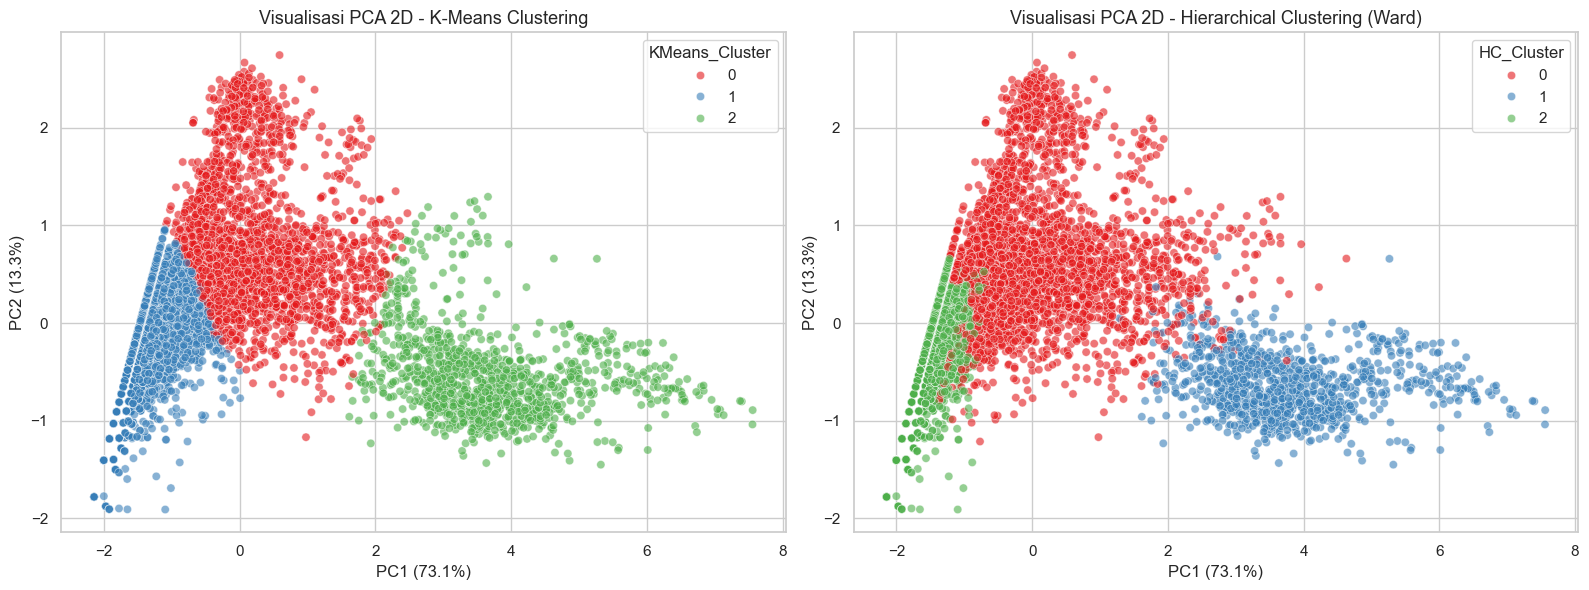

In [163]:
# Lakukan PCA ke 2 komponen pada X_log_scaled.
# Tampilkan scatter plot hasil clustering K-Means dan Hierarchical Clustering dalam satu baris subplot, diwarnai berdasarkan label cluster.
# Tampilkan juga persentase varians yang dijelaskan oleh kedua komponen PCA.
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_log_scaled)

var_ratio = pca.explained_variance_ratio_
total_var = var_ratio.sum() * 100

print(
    f"Persentase varians Komponen 1 (PC1): {var_ratio[0]*100:.2f}%, Komponen 2"
    f" (PC2): {var_ratio[1]*100:.2f}%"
)
print(f"Total varians yang dijelaskan oleh PCA 2D: {total_var:.2f}%\n")

pca_df = pd.DataFrame(
    {
        "PC1": X_pca[:, 0],
        "PC2": X_pca[:, 1],
        "KMeans_Cluster": df["kmeans_cluster"],
        "HC_Cluster": df["hc_cluster"],
    }
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="KMeans_Cluster",
    palette="Set1",
    alpha=0.6,
    ax=axes[0],
)
axes[0].set_title("Visualisasi PCA 2D - K-Means Clustering", fontsize=13)
axes[0].set_xlabel(f"PC1 ({var_ratio[0]*100:.1f}%)")
axes[0].set_ylabel(f"PC2 ({var_ratio[1]*100:.1f}%)")

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="HC_Cluster",
    palette="Set1",
    alpha=0.6,
    ax=axes[1],
)
axes[1].set_title(
    "Visualisasi PCA 2D - Hierarchical Clustering (Ward)", fontsize=13
)
axes[1].set_xlabel(f"PC1 ({var_ratio[0]*100:.1f}%)")
axes[1].set_ylabel(f"PC2 ({var_ratio[1]*100:.1f}%)")

plt.tight_layout()
plt.show()

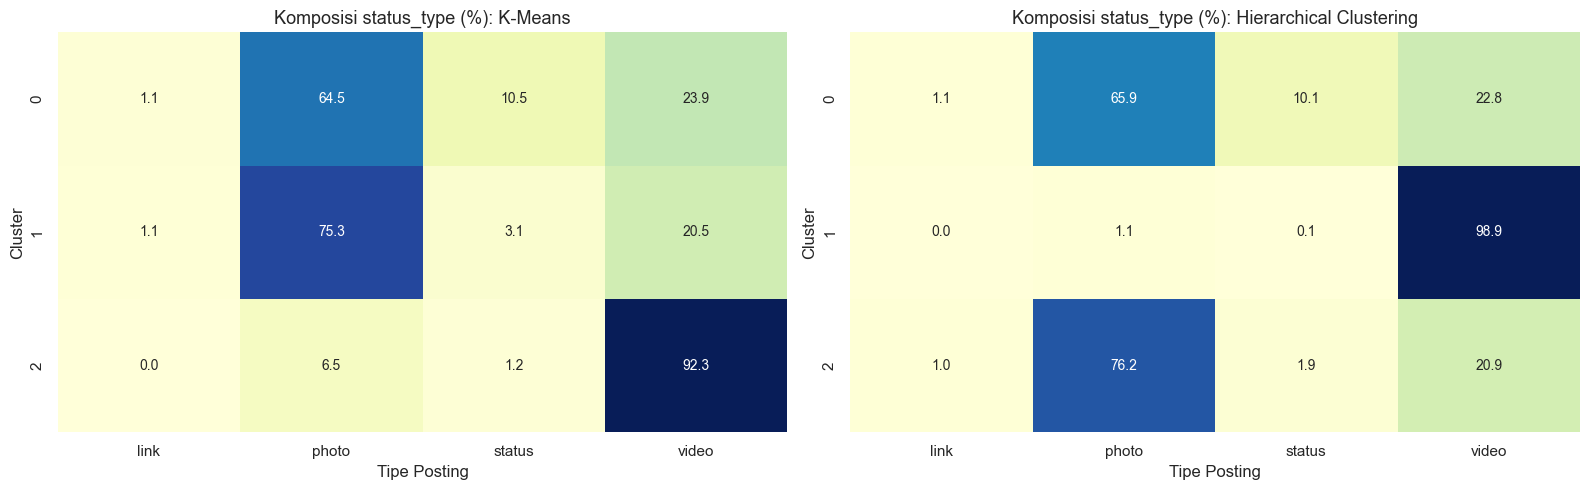

In [164]:
# Tampilkan komposisi status_type pada tiap cluster (crosstab dalam persen) untuk K-Means dan Hierarchical Clustering dalam bentuk heatmap.
# Susun keduanya dalam satu baris subplot.
# Ini hanya untuk membantu interpretasi cluster, bukan sebagai label asli.
ct_km = (
    pd.crosstab(
        df["kmeans_cluster"], df["status_type"], normalize="index"
    )
    * 100
)
ct_hc = (
    pd.crosstab(df["hc_cluster"], df["status_type"], normalize="index")
    * 100
)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.heatmap(ct_km, annot=True, fmt=".1f", cmap="YlGnBu", ax=axes[0], cbar=False)
axes[0].set_title("Komposisi status_type (%): K-Means", fontsize=13)
axes[0].set_xlabel("Tipe Posting")
axes[0].set_ylabel("Cluster")

sns.heatmap(ct_hc, annot=True, fmt=".1f", cmap="YlGnBu", ax=axes[1], cbar=False)
axes[1].set_title(
    "Komposisi status_type (%): Hierarchical Clustering", fontsize=13
)
axes[1].set_xlabel("Tipe Posting")
axes[1].set_ylabel("Cluster")

plt.tight_layout()
plt.show()

# 6. Analisis


### Pengaruh Transformasi Log dan Feature Scaling
Transformasi log1p dan StandardScaler berinteraksi secara signifikan dalam meningkatkan kualitas clustering K-Means. Pada data mentah X_raw, fitur num_comments dan num_likes memiliki varians yang sangat besar dengan rentang nilai mencapai 20990, sedangkan fitur lain seperti emoji bernilai jauh lebih kecil. Tanpa scaling dan transformasi log, jarak Euclidean didominasi sepenuhnya oleh fitur dengan skala besar. Akibatnya, clustering menghasilkan pembagian anggota yang sangat tidak seimbang di mana lebih dari 90 persen data terkumpul dalam satu cluster, dengan Silhouette Score hanya sebesar 0.2982 pada X_raw dan 0.2416 pada X_raw_scaled.

Penerapan log1p berhasil meredam skewness ekstrem dan efek outlier, sementara StandardScaler menyamakan skala seluruh fitur sehingga setiap variabel memiliki bobot yang setara. Kombinasi ini menghasilkan Silhouette Score tertinggi sebesar 0.4325 dan sebaran anggota cluster yang jauh lebih proporsional.

### Penanganan Kolom Redundan dan Sparse
Kolom status_id dihapus karena hanya berupa identitas baris. Kolom num_reactions dihilangkan karena memiliki korelasi mendekati sempurna dengan num_likes yaitu sebesar 0.99. Secara definisi num_reactions merupakan penjumlahan num_likes dengan reaksi emoji lainnya, sehingga menyertakannya akan menimbulkan pembobotan ganda pada interaksi dasar.

Fitur reaksi emoji num_wows, num_hahas, num_sads, dan num_angrys memiliki nilai nol mencapai 75 persen hingga 94 persen dari total baris. Untuk mengatasi kelangkaan data ini, keempat fitur tersebut digabungkan menjadi satu variabel bernama num_other_emojis. Fitur num_loves tetap dipisahkan karena merupakan reaksi positif yang paling sering digunakan setelah like. Fitur akhir yang dipilih adalah num_likes, num_comments, num_shares, num_loves, dan num_other_emojis.

### Penentuan Jumlah Cluster Optimal
Berdasarkan grafik Elbow Method, titik siku terbentuk pada k = 3 di mana penurunan nilai inertia melambat secara signifikan dari k = 2 ke k = 3. Sementara itu, pada evaluasi Silhouette Score, nilai tertinggi berada pada k = 2 sebesar 0.5871, diikuti oleh k = 3 sebesar 0.4325.

Nilai k = 3 dipilih sebagai jumlah cluster optimal karena memberikan interpretasi bisnis yang lebih substantif dibandingkan k = 2. Pada k = 2 data hanya terbagi menjadi postingan sepi dan postingan ramai. Dengan k = 3, model mampu memisahkan kelompok postingan menjadi tiga tingkatan engagement yang jelas yaitu interaksi rendah, interaksi sedang berbasis like, dan interaksi viral berbasis komentar serta share.

### Perbandingan Metode Linkage pada Hierarchical Clustering
Pengujian empat metode linkage pada k = 3 menunjukkan perbedaan karakteristik pembentukan cluster:
1. Ward: Menghasilkan Silhouette Score 0.3757 dengan sebaran anggota yang paling seimbang yaitu 2966, 1044, dan 2986 sampel.
2. Complete: Menghasilkan Silhouette Score 0.4783 dengan distribusi anggota 1246, 347, dan 5403 sampel.
3. Average: Menghasilkan Silhouette Score 0.5726 namun distribusinya tidak seimbang yaitu 5892, 1075, dan 29 sampel.
4. Single: Menghasilkan Silhouette Score 0.3526 dengan efek chaining yang sangat ekstrem di mana satu cluster berisi 6994 sampel, sementara dua cluster lainnya masing-masing hanya berisi 1 sampel.

Metode Ward merupakan linkage terbaik untuk dataset ini karena meminimalkan varians di dalam cluster sehingga tidak menghasilkan cluster kerdil. Karakteristik single linkage yang menggabungkan cluster berdasarkan jarak terdekat antar dua titik menyebabkan fenomena chaining, di mana outlier dipisahkan sebagai cluster tunggal sedangkan sisa data menumpuk dalam satu kelompok besar.

### Perbandingan K-Means vs Hierarchical Clustering
Hasil evaluasi metrik internal menunjukkan performa kedua algoritma:
- K-Means (k=3): Silhouette Score = 0.4325, Davies-Bouldin Index = 0.9541, Calinski-Harabasz Score = 8560.49.
- Hierarchical Clustering Ward (k=3): Silhouette Score = 0.3757, Davies-Bouldin Index = 0.9476, Calinski-Harabasz Score = 7591.12.

K-Means unggul pada Silhouette Score dan Calinski-Harabasz Score karena mekanisme pengerjaannya secara langsung mengoptimalkan centroid untuk meminimalkan Within-Cluster Sum of Squares pada ruang Euclidean. Visualisasi PCA 2D yang menjelaskan 86.47 persen total varians memperlihatkan bahwa kedua metode menghasilkan pola pemisahan ruang data yang serupa, namun K-Means memiliki batas antar cluster yang lebih tegas.

### Profil dan Karakteristik Tiap Cluster
Berdasarkan nilai median data asli dan analisis crosstab status_type, karakteristik cluster didefinisikan sebagai berikut:

1. Cluster Low Engagement (Postingan Sepi):
   Median num_likes = 18, num_comments = 0, num_shares = 0, num_loves = 0, num_other_emojis = 0. Didominasi oleh konten bertipe photo sebesar 75.3 persen dan video sebesar 20.5 persen. Cluster ini mencerminkan postingan dengan jangkauan rendah yang gagal memicu respon audiens.

2. Cluster Medium Engagement (Postingan Standar Berbasis Like):
   Median num_likes = 204.5, num_comments = 11, num_shares = 1, num_loves = 1, num_other_emojis = 0. Didominasi oleh photo sebesar 64.5 persen dan video sebesar 23.9 persen. Cluster ini merepresentasikan postingan harian yang sukses mendapatkan pasokan like dan apresiasi dasar secara konsisten.

3. Cluster High Engagement (Postingan Viral / High Engagement):
   Median num_likes = 177, num_comments = 703, num_shares = 174, num_loves = 51, num_other_emojis = 4. Didominasi secara mutlak oleh konten bertipe video sebesar 92.3 persen. Cluster ini menggambarkan postingan siaran langsung atau video jualan yang memicu diskusi intensif dan dibagikan secara masif oleh audiens.

### Kelebihan dan Kekurangan Metode
K-Means memiliki kelebihan pada kecepatan komputasi yang efisien dan kebutuhan memori yang rendah, sehingga sangat cocok untuk dataset berukuran besar seperti Live.csv. Kekurangannya adalah sensitif terhadap penentuan nilai k di awal serta mengasumsikan cluster berbentuk sferis.

Hierarchical Clustering memiliki kelebihan karena tidak mewajibkan penentuan k di awal dan menghasilkan gambaran hierarki data melalui dendrogram. Kekurangannya terletak pada kompleksitas komputasi dan memori yang tinggi, sehingga membutuhkan waktu eksekusi yang lebih lama dan kurang fleksibel untuk data berukuran sangat besar.



# 7. Kesimpulan dan Saran

### Kesimpulan
1. Preprocessing berupa transformasi log1p dan StandardScaler sangat krusial untuk algoritma clustering berbasis jarak. Tanpa kedua tahap ini, fitur bertipe count dengan skewness tinggi dan perbedaan skala ekstrem akan merusak pembentukan cluster.
2. Penanganan redundansi dengan menghapus num_reactions serta penggabungan reaksi emoji sparse menjadi num_other_emojis berhasil menyederhanakan ruang fitur tanpa kehilangan informasi penting.
3. Jumlah cluster optimal yang dipilih adalah k = 3 berdasarkan titik siku pada Elbow Method serta interpretasi tingkat engagement yang jelas (Low, Medium, dan High Engagement).
4. Metode linkage Ward merupakan pilihan terbaik pada Hierarchical Clustering karena menghasilkan sebaran anggota cluster yang paling seimbang, sedangkan metode single linkage mengalami kegagalan akibat efek chaining.
5. K-Means menunjukkan performa sedikit lebih unggul dibandingkan Hierarchical Clustering pada metrik Silhouette Score (0.4325 vs 0.3757) dan Calinski-Harabasz Score (8560.49 vs 7591.12), serta terbukti jauh lebih efisien dari segi waktu komputasi.
6. Tipe konten bertipe video memegang peranan kunci dalam mendorong interaksi mendalam seperti komentar, share, dan reaksi emoji, sedangkan konten bertipe photo lebih terbatas pada interaksi like dasar.

### Saran
1. Melakukan eksperimen clustering secara terpisah untuk periode sebelum tahun 2016 dan sesudah tahun 2016, mengingat fitur reaksi emoji baru tersedia di Facebook sejak 2016.
2. Memanfaatkan fitur temporal dari status_published seperti jam posting atau hari dalam seminggu untuk menganalisis waktu terbaik dalam mengunggah konten.
3. Mencoba algoritma clustering berbasis kerapatan seperti DBSCAN untuk mendeteksi outlier secara otomatis, atau Gaussian Mixture Model untuk menangani keterikatan cluster yang bersifat kontinu.
4. Menguji teknik reduksi dimensi seperti PCA atau UMAP sebelum proses clustering untuk melihat pengaruhnya terhadap efisiensi dan kualitas pemisahan cluster.